In [1]:

import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from collections import Counter

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

# 1. Write a paragraph
text = """I love technology and computers.
Python is an interesting programming language.
It helps us create useful applications.
Artificial intelligence makes computers smarter.
I enjoy learning new things about technology.
I want to become a good programmer in the future."""

print("Original Paragraph:")
print(text)

# 2. Convert to lowercase and remove punctuation
clean_text = re.sub(r'[^\w\s]', '', text.lower())

print("\nCleaned Text:")
print(clean_text)

# 3. Split into sentences and words
sentences = sent_tokenize(text)
words = word_tokenize(text)

print("\nSentences:")
print(sentences)

print("\nWords using word_tokenize():")
print(words)

# 4. Compare split() and word_tokenize()
print("\nUsing split():")
print(text.split())

print("\nUsing word_tokenize():")
print(word_tokenize(text))

# 5. Remove stopwords
stop_words = set(stopwords.words('english'))
clean_words = word_tokenize(clean_text)

final_words = []
for word in clean_words:
    if word not in stop_words:
        final_words.append(word)

print("\nWords after removing stopwords:")
print(final_words)

# 6. Count word frequencies
frequency = Counter(final_words)

print("\nWord Frequency:")
print(frequency)


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Original Paragraph:
I love technology and computers.
Python is an interesting programming language.
It helps us create useful applications.
Artificial intelligence makes computers smarter.
I enjoy learning new things about technology.
I want to become a good programmer in the future.

Cleaned Text:
i love technology and computers
python is an interesting programming language
it helps us create useful applications
artificial intelligence makes computers smarter
i enjoy learning new things about technology
i want to become a good programmer in the future

Sentences:
['I love technology and computers.', 'Python is an interesting programming language.', 'It helps us create useful applications.', 'Artificial intelligence makes computers smarter.', 'I enjoy learning new things about technology.', 'I want to become a good programmer in the future.']

Words using word_tokenize():
['I', 'love', 'technology', 'and', 'computers', '.', 'Python', 'is', 'an', 'interesting', 'programming', 'language'

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [2]:

import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

# Download required resources
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

# 1. Use the same paragraph from Q1
text = """I love technology and computers.
Python is an interesting programming language.
It helps us create useful applications.
Artificial intelligence makes computers smarter.
I enjoy learning new things about technology.
I want to become a good programmer in the future."""

# Convert to lowercase
text = text.lower()

# 2. Extract words containing only alphabets
words = re.findall(r'\b[a-zA-Z]+\b', text)

print("Words containing only alphabets:")
print(words)

# 3. Remove stopwords
stop_words = set(stopwords.words('english'))

filtered_words = []
for word in words:
    if word not in stop_words:
        filtered_words.append(word)

print("\nAfter removing stopwords:")
print(filtered_words)

# 4. Perform stemming using PorterStemmer
porter = PorterStemmer()

stemmed_words = []
for word in filtered_words:
    stemmed_words.append(porter.stem(word))

print("\nStemmed words:")
print(stemmed_words)

# 5. Perform lemmatization using WordNetLemmatizer
lemmatizer = WordNetLemmatizer()

lemmatized_words = []
for word in filtered_words:
    lemmatized_words.append(lemmatizer.lemmatize(word))

print("\nLemmatized words:")
print(lemmatized_words)

# 6. Compare the outputs
print("\nComparison:")
for i in range(len(filtered_words)):
    print(filtered_words[i], "-> Stem:", stemmed_words[i],
          "| Lemma:", lemmatized_words[i])


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Words containing only alphabets:
['i', 'love', 'technology', 'and', 'computers', 'python', 'is', 'an', 'interesting', 'programming', 'language', 'it', 'helps', 'us', 'create', 'useful', 'applications', 'artificial', 'intelligence', 'makes', 'computers', 'smarter', 'i', 'enjoy', 'learning', 'new', 'things', 'about', 'technology', 'i', 'want', 'to', 'become', 'a', 'good', 'programmer', 'in', 'the', 'future']

After removing stopwords:
['love', 'technology', 'computers', 'python', 'interesting', 'programming', 'language', 'helps', 'us', 'create', 'useful', 'applications', 'artificial', 'intelligence', 'makes', 'computers', 'smarter', 'enjoy', 'learning', 'new', 'things', 'technology', 'want', 'become', 'good', 'programmer', 'future']

Stemmed words:
['love', 'technolog', 'comput', 'python', 'interest', 'program', 'languag', 'help', 'us', 'creat', 'use', 'applic', 'artifici', 'intellig', 'make', 'comput', 'smarter', 'enjoy', 'learn', 'new', 'thing', 'technolog', 'want', 'becom', 'good', 'p

In [3]:

# Q3: Bag of Words and TF-IDF

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# 1. Three short texts of our own
texts = [
    "This laptop is fast and the battery lasts long.",
    "The laptop battery is good but the laptop is expensive.",
    "This phone has a great camera and good battery life."
]

# 2. Bag of Words using CountVectorizer
count_vectorizer = CountVectorizer()
bow_matrix = count_vectorizer.fit_transform(texts)

print("BAG OF WORDS")
print("Words:", count_vectorizer.get_feature_names_out())
print(bow_matrix.toarray())

# 3. TF-IDF calculation
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)

words = tfidf_vectorizer.get_feature_names_out()

print("\nTF-IDF SCORES")
print("Words:", words)
print(tfidf_matrix.toarray().round(3))

# 4. Print the top 3 keywords from each text
print("\nTOP 3 KEYWORDS FOR EACH TEXT")

for i in range(len(texts)):
    scores = tfidf_matrix[i].toarray().flatten()

    # Get indices of the 3 highest TF-IDF scores
    top_indices = scores.argsort()[-3:][::-1]

    print(f"\nText {i + 1}: {texts[i]}")
    for index in top_indices:
        print(words[index], ":", round(scores[index], 3))


BAG OF WORDS
Words: ['and' 'battery' 'but' 'camera' 'expensive' 'fast' 'good' 'great' 'has'
 'is' 'laptop' 'lasts' 'life' 'long' 'phone' 'the' 'this']
[[1 1 0 0 0 1 0 0 0 1 1 1 0 1 0 1 1]
 [0 1 1 0 1 0 1 0 0 2 2 0 0 0 0 2 0]
 [1 1 0 1 0 0 1 1 1 0 0 0 1 0 1 0 1]]

TF-IDF SCORES
Words: ['and' 'battery' 'but' 'camera' 'expensive' 'fast' 'good' 'great' 'has'
 'is' 'laptop' 'lasts' 'life' 'long' 'phone' 'the' 'this']
[[0.304 0.236 0.    0.    0.    0.4   0.    0.    0.    0.304 0.304 0.4
  0.    0.4   0.    0.304 0.304]
 [0.    0.188 0.318 0.    0.318 0.    0.242 0.    0.    0.484 0.484 0.
  0.    0.    0.    0.484 0.   ]
 [0.286 0.222 0.    0.376 0.    0.    0.286 0.376 0.376 0.    0.    0.
  0.376 0.    0.376 0.    0.286]]

TOP 3 KEYWORDS FOR EACH TEXT

Text 1: This laptop is fast and the battery lasts long.
long : 0.4
fast : 0.4
lasts : 0.4

Text 2: The laptop battery is good but the laptop is expensive.
the : 0.484
is : 0.484
laptop : 0.484

Text 3: This phone has a great camera and goo

In [4]:

# Q4: Text Similarity

import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# 1. Write two short texts (4-6 lines each)

text1 = """
Artificial intelligence helps computers learn from data.
AI can recognize images and understand human language.
It is used in healthcare, education, and robotics.
AI systems can make predictions and automate tasks.
"""

text2 = """
Blockchain stores information in secure digital blocks.
It is used for cryptocurrency and secure transactions.
Blockchain records are difficult to change.
This technology improves transparency and trust.
"""

print("TEXT 1: ARTIFICIAL INTELLIGENCE")
print(text1)

print("TEXT 2: BLOCKCHAIN")
print(text2)


# 2. Preprocess and tokenize both texts

def preprocess(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    words = text.split()
    return words

words1 = preprocess(text1)
words2 = preprocess(text2)

print("Tokens of Text 1:")
print(words1)

print("\nTokens of Text 2:")
print(words2)


# 3a. Calculate Jaccard Similarity

set1 = set(words1)
set2 = set(words2)

common_words = set1.intersection(set2)
all_words = set1.union(set2)

jaccard = len(common_words) / len(all_words)

print("\nJACCARD SIMILARITY")
print("Common words:", common_words)
print("Jaccard Similarity:", round(jaccard, 3))


# 3b. Calculate Cosine Similarity using TF-IDF

texts = [text1, text2]

vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform(texts)

cosine = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:2])[0][0]

print("\nCOSINE SIMILARITY")
print("Cosine Similarity:", round(cosine, 3))


# 4. Compare the results

print("\nCOMPARISON")
print("Jaccard Similarity:", round(jaccard, 3))
print("Cosine Similarity:", round(cosine, 3))


TEXT 1: ARTIFICIAL INTELLIGENCE

Artificial intelligence helps computers learn from data.
AI can recognize images and understand human language.
It is used in healthcare, education, and robotics.
AI systems can make predictions and automate tasks.

TEXT 2: BLOCKCHAIN

Blockchain stores information in secure digital blocks.
It is used for cryptocurrency and secure transactions.
Blockchain records are difficult to change.
This technology improves transparency and trust.

Tokens of Text 1:
['artificial', 'intelligence', 'helps', 'computers', 'learn', 'from', 'data', 'ai', 'can', 'recognize', 'images', 'and', 'understand', 'human', 'language', 'it', 'is', 'used', 'in', 'healthcare', 'education', 'and', 'robotics', 'ai', 'systems', 'can', 'make', 'predictions', 'and', 'automate', 'tasks']

Tokens of Text 2:
['blockchain', 'stores', 'information', 'in', 'secure', 'digital', 'blocks', 'it', 'is', 'used', 'for', 'cryptocurrency', 'and', 'secure', 'transactions', 'blockchain', 'records', 'are',


Review 1 : This laptop is excellent and very fast. I love its performance.
Polarity: 0.59
Subjectivity: 0.79
Sentiment: Positive

Review 2 : The laptop is terrible and slow. I am very disappointed.
Polarity: -0.76
Subjectivity: 0.79
Sentiment: Negative

Review 3 : The laptop is okay. It works as expected.
Polarity: 0.2
Subjectivity: 0.45
Sentiment: Positive


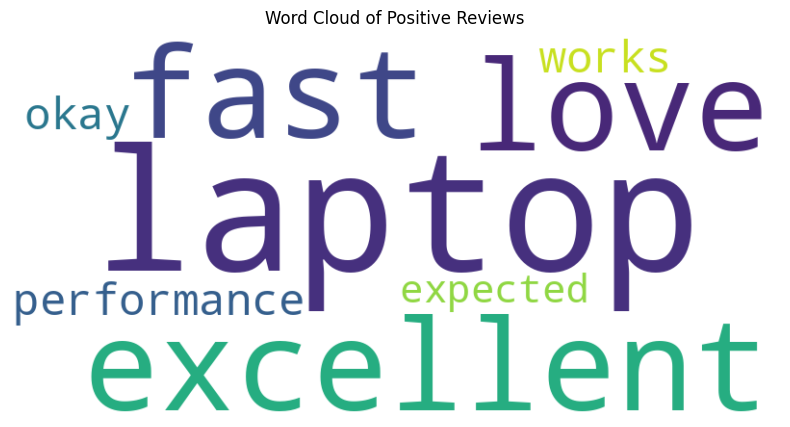

In [5]:

# Q5: Sentiment Analysis and Word Cloud

from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# 1. Write three laptop reviews
reviews = [
    "This laptop is excellent and very fast. I love its performance.",
    "The laptop is terrible and slow. I am very disappointed.",
    "The laptop is okay. It works as expected."
]

# Store positive reviews for the word cloud
positive_reviews = []

# 2. Find polarity, subjectivity and sentiment
for i, review in enumerate(reviews, start=1):

    analysis = TextBlob(review)

    polarity = analysis.sentiment.polarity
    subjectivity = analysis.sentiment.subjectivity

    # Classify the review
    if polarity > 0:
        sentiment = "Positive"
        positive_reviews.append(review)
    elif polarity < 0:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print("\nReview", i, ":", review)
    print("Polarity:", round(polarity, 2))
    print("Subjectivity:", round(subjectivity, 2))
    print("Sentiment:", sentiment)


# 3. Create a word cloud from positive reviews
if positive_reviews:

    positive_text = " ".join(positive_reviews)

    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color="white"
    ).generate(positive_text)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word Cloud of Positive Reviews")
    plt.show()


In [ ]:

# Q6: Text Generation using LSTM

import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

# 1. Training paragraph (~100 words)
text = """
Technology makes our lives easier and more connected.
Computers help us solve problems and learn new skills.
Artificial intelligence helps machines learn from data.
Python is a popular language for building useful applications.
Students use technology to study and explore new ideas.
The internet allows people to share information quickly.
Machine learning helps computers recognize patterns.
Good technology should be safe and easy to use.
Learning programming improves creativity and logical thinking.
In the future, technology will continue to change our world.
"""

# 2. Tokenize the text
tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])

total_words = len(tokenizer.word_index) + 1

print("Total unique words:", total_words)

# Convert words into numbers
tokens = tokenizer.texts_to_sequences([text])[0]

# 3. Create input sequences
sequences = []

for i in range(1, len(tokens)):
    sequences.append(tokens[:i + 1])

# Make sequences equal in length
max_length = max(len(seq) for seq in sequences)
sequences = pad_sequences(sequences, maxlen=max_length)

# Separate input (X) and target (y)
X = sequences[:, :-1]
y = sequences[:, -1]

# 4. Build a simple LSTM model
model = Sequential([
    Embedding(total_words, 16),
    LSTM(32),
    Dense(total_words, activation="softmax")
])

model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

# 5. Train the model
model.fit(X, y, epochs=100, verbose=0)

print("Model training completed!")

# 6. Generate new text
def generate_text(seed_word, next_words=8):

    result = seed_word.lower()

    for _ in range(next_words):

        sequence = tokenizer.texts_to_sequences([result])[0]
        sequence = pad_sequences(
            [sequence],
            maxlen=max_length - 1,
            padding="pre"
        )

        prediction = model.predict(sequence, verbose=0)
        predicted_id = np.argmax(prediction, axis=1)[0]

        output_word = ""

        for word, index in tokenizer.word_index.items():
            if index == predicted_id:
                output_word = word
                break

        if not output_word:
            break

        result += " " + output_word

    return result


# Generate 2-3 lines using different seed words
print("\nGENERATED TEXT:")

print("1.", generate_text("technology", 8))
print("2.", generate_text("computers", 8))
print("3.", generate_text("learning", 8))


Total unique words: 65
